In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # project root containing app/

%load_ext autoreload
%autoreload 2


In [13]:
from app.config import BASE_DIR
print(BASE_DIR, (BASE_DIR / ".env").exists())

/Volumes/Personal/projects/fastapi/deepwell True


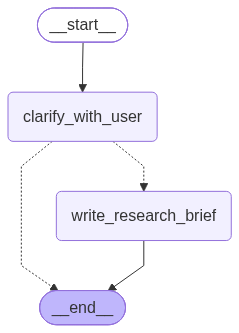

In [ ]:
from app.agents.scope.agent import build
from IPython.display import Image, display
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.config import RunnableConfig

checkpointer = InMemorySaver()
store = InMemoryStore()
agent = build(checkpointer=checkpointer, store=store)


display(Image(agent.get_graph().draw_mermaid_png()))

In [ ]:
config: RunnableConfig = {"configurable": {"thread_id": "1", "user_id" : "rizwan"}}
from langchain_core.messages import HumanMessage

response = agent.ainvoke({"messages": [HumanMessage(content="I have BS in computer science, i am looking to find MS programs in Germany")]}, config=config)

for m in response["messages"]:
    m.pretty_print()

TypeError: No synchronous function provided to "clarify_with_user".
Either initialize with a synchronous function or invoke via the async API (ainvoke, astream, etc.)